# [Lab Session 4](deconvolution.ipynb)

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from skimage.restoration import wiener
from scipy.signal import convolve2d as conv
from scipy.stats import multivariate_normal as multi_normal

np.random.seed(0)

Load the image.

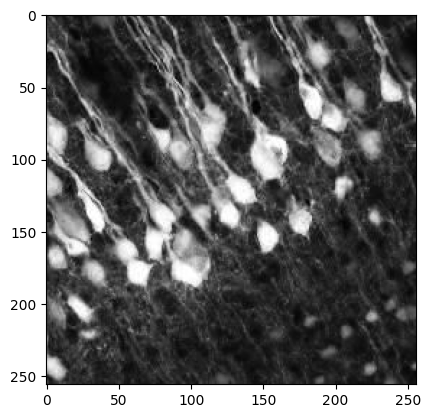

In [3]:
img = plt.imread('data/cells.png')[128:384, 128:384]
plt.imshow(img, 'gray')

**[Task 1.]()** Apply the following PSF to the image and then display it.

In [4]:
psf_size = 10
psf = np.ones((psf_size, psf_size)) / psf_size ** 2

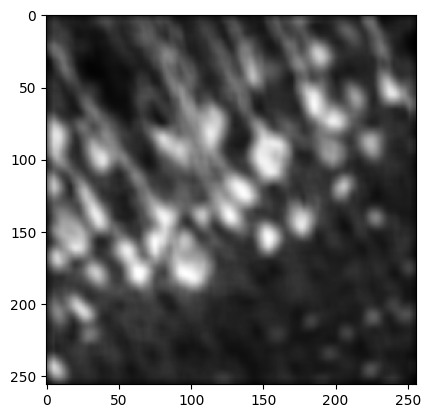

In [6]:
psf_img = conv(img, psf, mode='same')

plt.imshow(psf_img, cmap='gray')
plt.show()

**[Task 2.]()** Have a look at the Gaussian PSF which is not uniformly distributed. Apply it to the image.

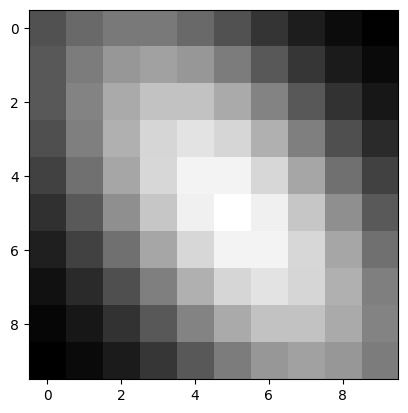

In [7]:
def create_psf(size):
    factor = size * 1.8
    x, y = np.mgrid[0:size:1, 0:size:1]
    pos = np.empty(x.shape + (2,))
    pos[:, :, 0] = x
    pos[:, :, 1] = y
    rv = multi_normal([int(size / 2), (int(size / 2))], [[factor * 1., factor * 1.2], [factor * .5, factor * .7]])
    return rv.pdf(pos)

plt.imshow(create_psf(psf_size), 'gray')

Apply the second psf to the image:

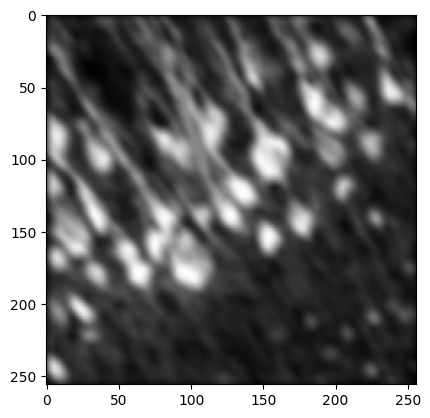

In [10]:
gaussian_psf = create_psf(psf_size)
gaussian_psf_img = conv(img, gaussian_psf, mode='same')

plt.imshow(gaussian_psf_img, cmap='gray')
plt.show()

**[Task 3.]()** Implement a reusable function that performs the Richardson-Lucy deconvolution.

In [12]:
def richardson_lucy_deconvolution(image, psf, n_iterations):
    img_deconv = np.full(image.shape, 0.5)
    flipped_psf = np.flip(psf)

    for i in range(n_iterations):
        blurred = conv(img_deconv, psf, mode='same')
        ratio = image / (blurred + 1e-10)
        correction = conv(ratio, flipped_psf, mode='same')
        img_deconv = img_deconv * correction

    img_deconv = img_deconv.clip(0, 1)
    return img_deconv

--> Blur the current estimate.
--> Compare the observed image with that blurred estimate by dividing.
--> Convolve the ratio with the flipped PSF.
--> Multiply the estimate by this correction.

**[Task 4.]()** Apply the Richardson-Lucy deconvolution to the blurred image.

In [15]:
restored = richardson_lucy_deconvolution(psf_img, psf, 30)


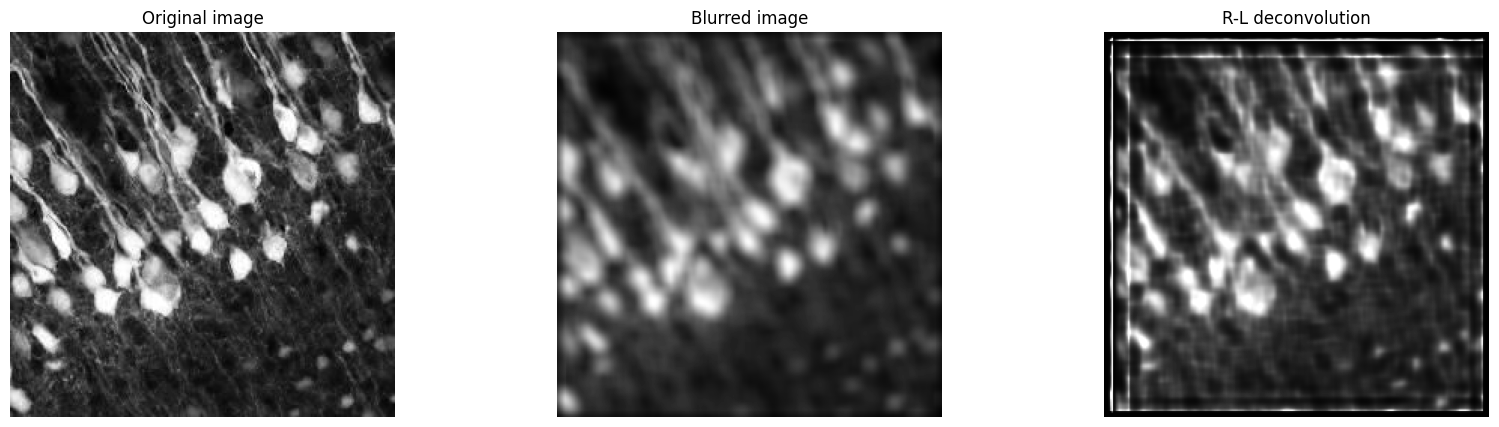

In [16]:
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')

plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(psf_img, 'gray')
plt.title('Blurred image')

plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(restored, 'gray')
plt.title('R-L deconvolution')

plt.show()

**[Task 5.]()** Add noise to the image, use the R-L deconvolution again.

In [17]:
noise = (np.random.normal(loc=0,size=img.shape))
reduce_factor = 5
noise = noise / reduce_factor

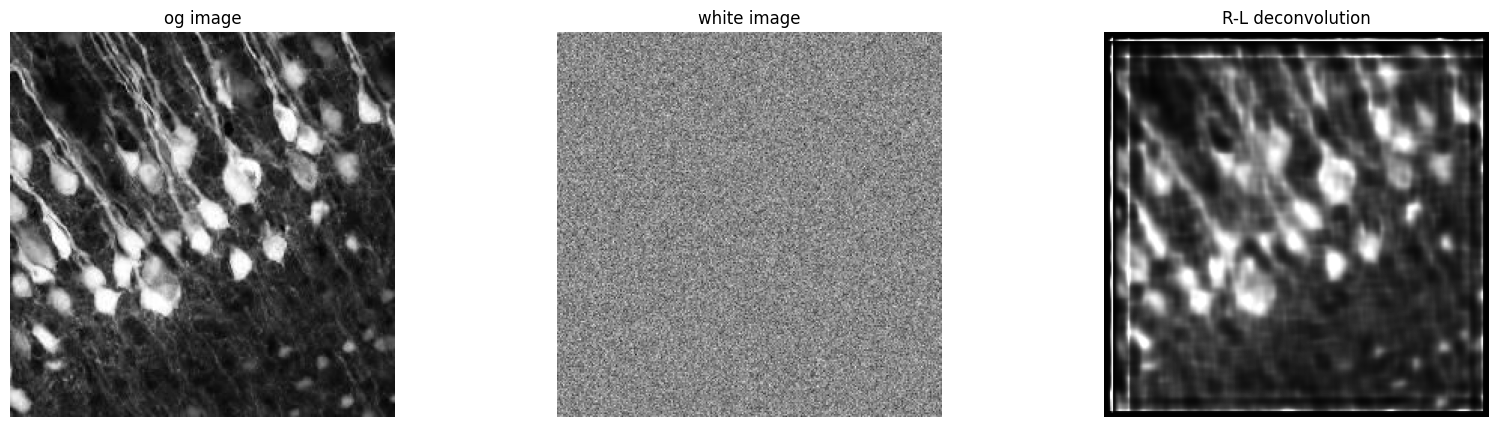

In [19]:
restored_white = richardson_lucy_deconvolution(noise, psf, 30)
plt.figure(figsize=(20, 5))

plt.subplot(1, 3, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('og image')

plt.subplot(1, 3, 2)
plt.axis('off')
plt.imshow(noise, 'gray')
plt.title('white image')

plt.subplot(1, 3, 3)
plt.axis('off')
plt.imshow(restored, 'gray')
plt.title('R-L deconvolution')

plt.show()

**[Task 6.]()** Compare your R-L implementation to a wiener deconvolution.

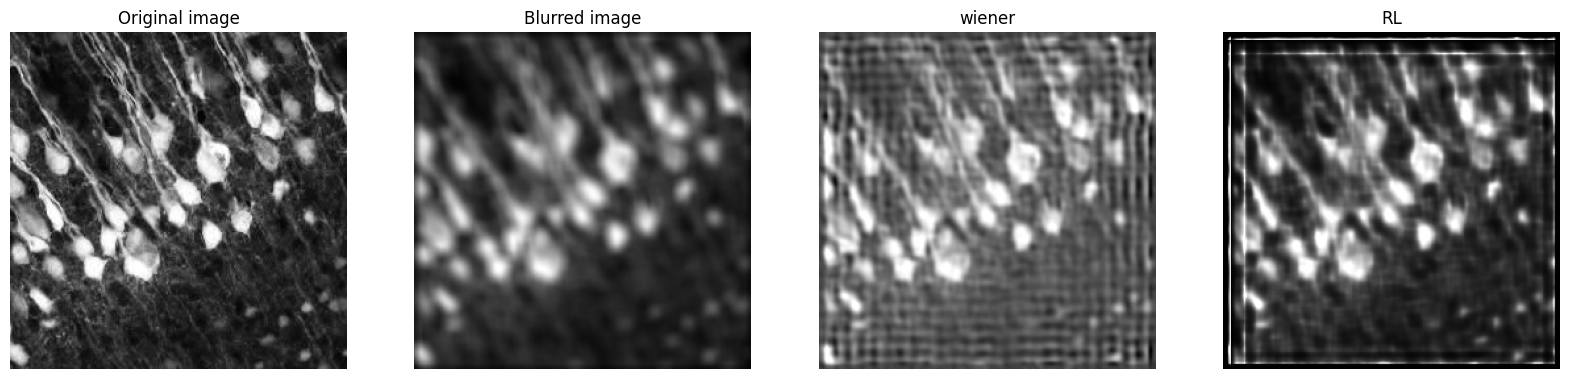

In [31]:
wiener_restored = wiener(psf_img, psf, balance=0.01, clip=True)
plt.figure(figsize=(20, 5))

plt.subplot(1, 4, 1)
plt.axis('off')
plt.imshow(img, 'gray')
plt.title('Original image')

plt.subplot(1, 4, 2)
plt.axis('off')
plt.imshow(psf_img, 'gray')
plt.title('Blurred image')

plt.subplot(1, 4, 3)
plt.axis('off')
plt.imshow(wiener_restored, 'gray')
plt.title('wiener')

plt.subplot(1, 4, 4)
plt.axis('off')
plt.imshow(restored, 'gray')
plt.title('RL')


plt.show()


**[Task 7.]()** Repeat Tasks 4–6 using a smaller value for the size of the PSF.

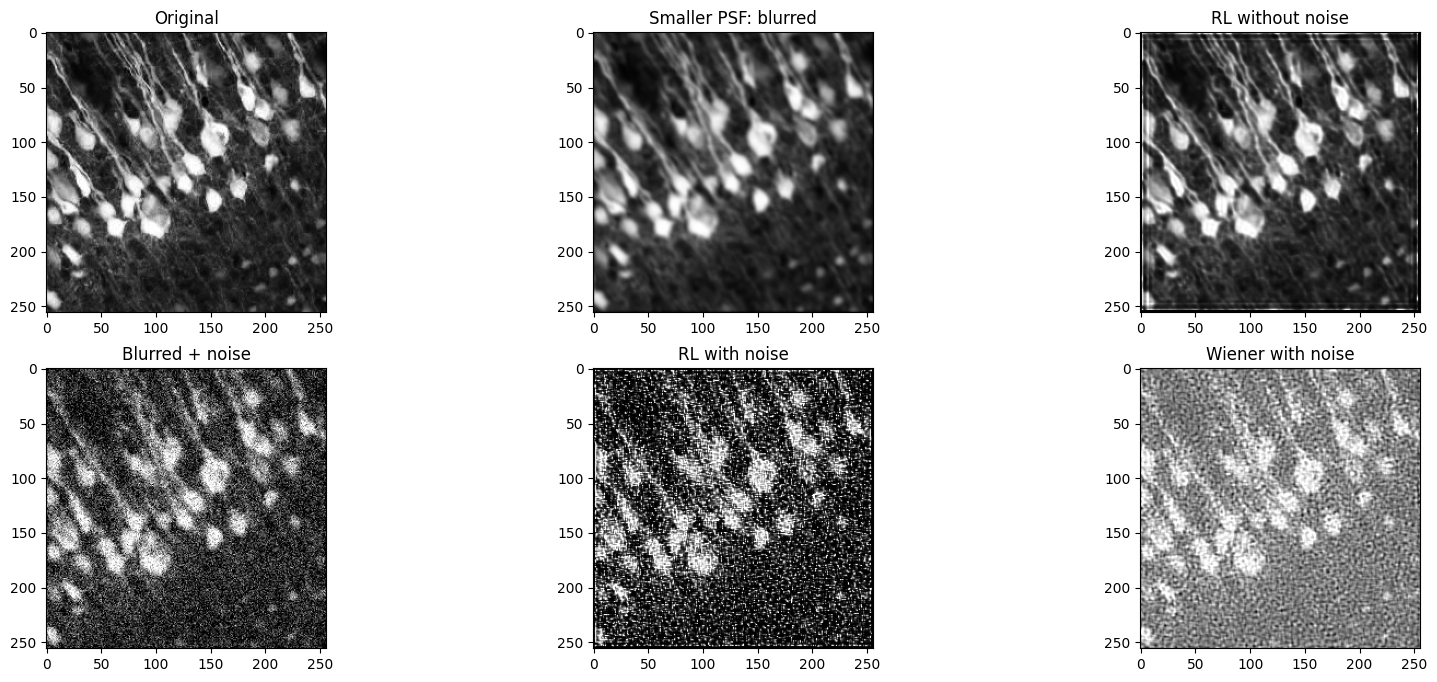

In [34]:
psf_size = 5
small_psf = create_psf(psf_size)
small_psf = small_psf / small_psf.sum()

small_blurred = conv(img, small_psf, mode='same')
small_restored = richardson_lucy_deconvolution(small_blurred, small_psf, 30)

small_noisy = (small_blurred + noise).clip(0, 1)
small_restored_noisy = richardson_lucy_deconvolution(small_noisy, small_psf, 30)
small_wiener = wiener(small_noisy, small_psf, balance=0.01)

plt.figure(figsize=(20, 8))

plt.subplot(2, 3, 1)
plt.imshow(img, cmap='gray')
plt.title('Original')

plt.subplot(2, 3, 2)
plt.imshow(small_blurred, cmap='gray')
plt.title('Smaller PSF: blurred')

plt.subplot(2, 3, 3)
plt.imshow(small_restored, cmap='gray')
plt.title('RL without noise')

plt.subplot(2, 3, 4)
plt.imshow(small_noisy, cmap='gray')
plt.title('Blurred + noise')

plt.subplot(2, 3, 5)
plt.imshow(small_restored_noisy, cmap='gray')
plt.title('RL with noise')

plt.subplot(2, 3, 6)
plt.imshow(small_wiener, cmap='gray')
plt.title('Wiener with noise')

plt.show()

**[Task 8.]()** Use a wrong PSF to restore the image

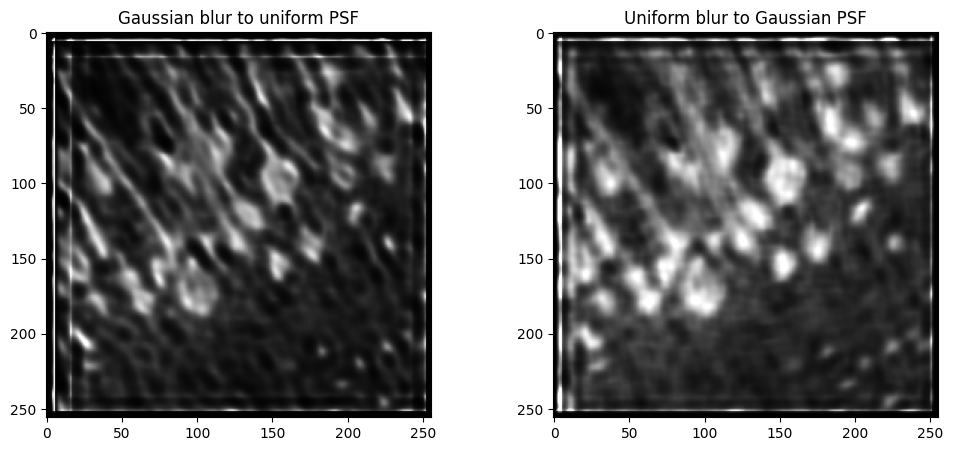

In [36]:
wrong_uniform = richardson_lucy_deconvolution(
    gaussian_psf_img, psf, 30
)

wrong_gaussian = richardson_lucy_deconvolution(
    psf_img, gaussian_psf, 30
)

plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(wrong_uniform, cmap='gray')
plt.title('Gaussian blur to uniform PSF')

plt.subplot(1, 2, 2)
plt.imshow(wrong_gaussian, cmap='gray')
plt.title('Uniform blur to Gaussian PSF')

plt.show()